# Phase I: Data Curation, Taxonomy Harmonization, EDA & Unsupervised Retrieval Baselines
### Manuscript Title: *Early Fusion of Dual-Transformer Embeddings with an XGBoost Meta-Learner for Automated Resume Classification*
### IEEE Access | Manuscript Tracking: **Access-2026-45264**
---
## Overview of Phase I Experimental Pipeline
Phase I investigates whether heuristic nearest-neighbor matching against category-aggregated job descriptions can reliably classify unstructured resumes without task-specific supervision.
This notebook implements:
1. **Ingestion & Provenance:** Loading raw candidate resumes (LiveCareer, CC0-1.0) and vacancy postings (JobStreet, CC BY 4.0).
2. **Taxonomy Harmonization:** Aligning 18 JobStreet market sectors and 24 LiveCareer categories into 17 unified professional domains.
3. **Exploratory Data Analysis (EDA):** Quantifying document length asymmetry, vocabulary distributions, and class frequencies (Figures 1, 2, and 3).
4. **Lexical Retrieval Baseline:** TF-IDF + Cosine matching on the held-out test partition (=376$), evaluating per-class F1 performance (Figure 6).
5. **Similarity Score Overlap:** Analyzing cosine similarity distributions for correct vs. incorrect classifications (Figure 7).
6. **Unsupervised Linear Hybrid Retrieval:** Combining MPNet dense semantics and TF-IDF lexical scores across $\\alpha \\in [0.0, 1.0]$.
7. **Diagnostic Confusion Matrix:** Visualizing residual semantic misclassification patterns at optimal $\\alpha = 0.90$ (Figure 8).


## 1. Environment Setup & Software Specifications


In [1]:
import transformers
print(transformers.__version__)

from transformers import BertTokenizer, BertForSequenceClassification
print("BERT import works")


5.0.0
BERT import works


In [2]:
import torch

print("CUDA Available:", torch.cuda.is_available())
print("Torch Version:", torch.__version__)
print("CUDA Version in Torch:", torch.version.cuda)


CUDA Available: True
Torch Version: 2.10.0+cu128
CUDA Version in Torch: 12.8


In [3]:
import pandas as pd

df = pd.read_csv("hf://datasets/azrai99/job-dataset/jobstreet_all_job_dataset.csv")
unique_categories = df["category"].unique()

print(unique_categories)


['Manufacturing, Transport & Logistics' 'Accounting' 'Engineering'
 'Administration & Office Support'
 'Information & Communication Technology' 'Human Resources & Recruitment'
 'Sales' 'Banking & Financial Services' 'Construction'
 'Consulting & Strategy' 'Design & Architecture'
 'Advertising, Arts & Media' 'CEO & General Management'
 'Trades & Services' 'Science & Technology'
 'Call Centre & Customer Service' 'Marketing & Communications'
 'Education & Training' 'Insurance & Superannuation'
 'Healthcare & Medical' 'Mining, Resources & Energy'
 'Hospitality & Tourism' 'Retail & Consumer Products'
 'Government & Defence' 'Legal' 'Real Estate & Property'
 'Farming, Animals & Conservation' 'Sport & Recreation'
 'Community Services & Development' 'Self Employment']


In [4]:
!pip install datasets --quiet

In [5]:
import pandas as pd
from datasets import load_dataset



## 2. Dataset Ingestion & Cross-Corpus Taxonomy Harmonization
Raw resumes (=2,484$ across 24 domains) and job vacancies (=59,300$ across 30 industries) are ingested.
The 18-to-17 category mapping dictionary is applied to establish an aligned multi-class benchmark (=1,880$ resumes, =42,487$ job descriptions across 17 professional classes).


In [6]:
import pandas as pd

# Load Azrai job dataset
job_df = pd.read_csv("hf://datasets/azrai99/job-dataset/jobstreet_all_job_dataset.csv")

# Load OpenSparks resume dataset
resume_df = pd.read_csv("hf://datasets/opensporks/resumes/Resume/Resume.csv")

resume_df["Category"] = resume_df["Category"].str.strip().str.upper()

print(resume_df["Category"].unique())


['HR' 'DESIGNER' 'INFORMATION-TECHNOLOGY' 'TEACHER' 'ADVOCATE'
 'BUSINESS-DEVELOPMENT' 'HEALTHCARE' 'FITNESS' 'AGRICULTURE' 'BPO' 'SALES'
 'CONSULTANT' 'DIGITAL-MEDIA' 'AUTOMOBILE' 'CHEF' 'FINANCE' 'APPAREL'
 'ENGINEERING' 'ACCOUNTANT' 'CONSTRUCTION' 'PUBLIC-RELATIONS' 'BANKING'
 'ARTS' 'AVIATION']


In [7]:
category_mapping = {
    "Human Resources & Recruitment": "HR",
    "Accounting": "ACCOUNTANT",
    "Engineering": "ENGINEERING",
    "Information & Communication Technology": "INFORMATION-TECHNOLOGY",
    "Sales": "SALES",
    "Retail & Consumer Products": "SALES",
    "Banking & Financial Services": "BANKING",
    "Insurance & Superannuation": "FINANCE",
    "Construction": "CONSTRUCTION",
    "Consulting & Strategy": "CONSULTANT",
    "CEO & General Management": "BUSINESS-DEVELOPMENT",
    "Design & Architecture": "DESIGNER",
    "Advertising, Arts & Media": "DIGITAL-MEDIA",
    "Education & Training": "TEACHER",
    "Healthcare & Medical": "HEALTHCARE",
    "Legal": "ADVOCATE",
    "Farming, Animals & Conservation": "AGRICULTURE",
    "Sport & Recreation": "FITNESS"
}


In [8]:
# Map Azrai categories to OpenSparks taxonomy
job_df["Mapped_Category"] = job_df["category"].map(category_mapping)

# Drop rows without mapping
job_df = job_df.dropna(subset=["Mapped_Category"]).copy()

# Keep only required columns
job_df_clean = job_df[["job_title", "descriptions", "Mapped_Category"]]

job_df_clean.head()


,job_title,descriptions,Mapped_Category
1,Account Executive/ Assistant,We are looking for a Account Executive/ Assist...,ACCOUNTANT
3,Service Engineer,"You are important for troubleshooting, install...",ENGINEERING
5,Accounts Executive,Job Responsibilities\nManage accounts payable ...,ACCOUNTANT
6,Accounts Executive,To assist in overall acounting functions for t...,ACCOUNTANT
7,PURCHASING EXECUTIVE,PURCHASING EXECUTIVE\nBachelor’s Degree in Bus...,ENGINEERING


In [9]:
valid_categories = list(set(category_mapping.values()))

resume_df_clean = resume_df[resume_df["Category"].isin(valid_categories)]
print("Resume Category Distribution:")
print(resume_df_clean["Category"].value_counts())

print("\nJob Category Distribution:")
print(job_df_clean["Mapped_Category"].value_counts())


Resume Category Distribution:
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ENGINEERING               118
ADVOCATE                  118
FINANCE                   118
ACCOUNTANT                118
FITNESS                   117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
HR                        110
DESIGNER                  107
TEACHER                   102
DIGITAL-MEDIA              96
AGRICULTURE                63
Name: count, dtype: int64

Job Category Distribution:
Mapped_Category
ACCOUNTANT                9983
ENGINEERING               8092
INFORMATION-TECHNOLOGY    7872
SALES                     5898
HR                        3714
BANKING                   2362
CONSTRUCTION              1283
DESIGNER                   701
HEALTHCARE                 677
TEACHER                    602
DIGITAL-MEDIA              333
ADVOCATE                   315
CONSULTAN

In [10]:
resume_df_clean.to_csv("clean_resumes.csv", index=False)
job_df_clean.to_csv("clean_job_descriptions.csv", index=False)

## 3. Exploratory Data Analysis (EDA)
Characterizing class sample distributions, document word length distributions (mean 811 words in resumes vs. 254 words in job descriptions), and vocabulary frequency profiles (Figures 1, 2, and 3 in the manuscript).


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter
import re

# Load cleaned files
resume_df = pd.read_csv("clean_resumes.csv")
job_df = pd.read_csv("clean_job_descriptions.csv")

print(resume_df.shape)
print(job_df.shape)


(1880, 4)
(42487, 3)


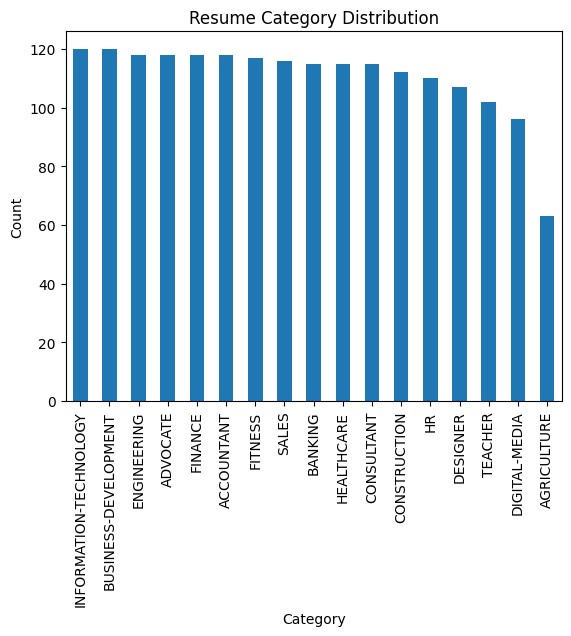

In [12]:
plt.figure()
resume_df["Category"].value_counts().plot(kind='bar')
plt.title("Resume Category Distribution")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()


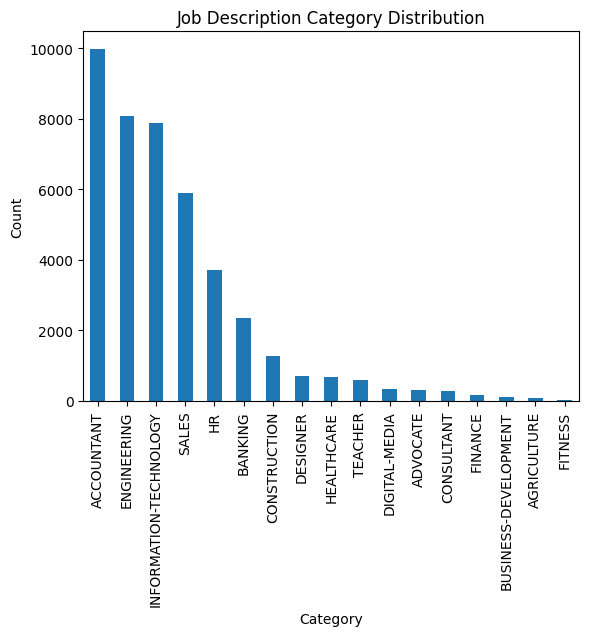

In [13]:
plt.figure()
job_df["Mapped_Category"].value_counts().plot(kind='bar')
plt.title("Job Description Category Distribution")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()


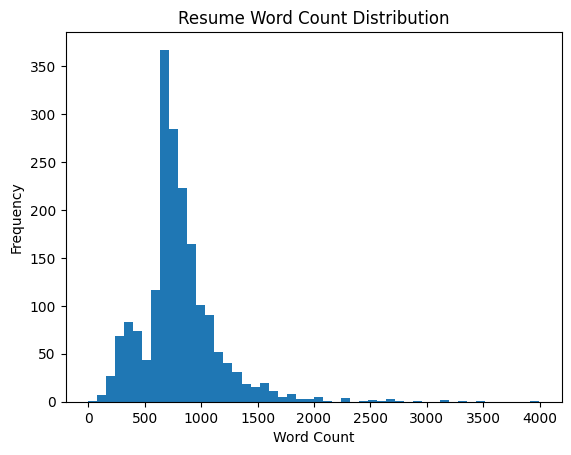

Resume Avg Length: 810.6021276595744


In [14]:
resume_df["resume_length"] = resume_df["Resume_str"].apply(lambda x: len(str(x).split()))

plt.figure()
plt.hist(resume_df["resume_length"], bins=50)
plt.title("Resume Word Count Distribution")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

print("Resume Avg Length:", resume_df["resume_length"].mean())


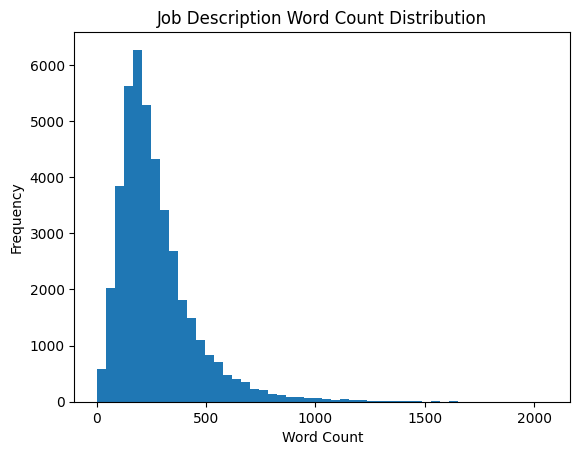

Job Description Avg Length: 271.3068703368089


In [15]:
job_df["job_length"] = job_df["descriptions"].apply(lambda x: len(str(x).split()))

plt.figure()
plt.hist(job_df["job_length"], bins=50)
plt.title("Job Description Word Count Distribution")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

print("Job Description Avg Length:", job_df["job_length"].mean())


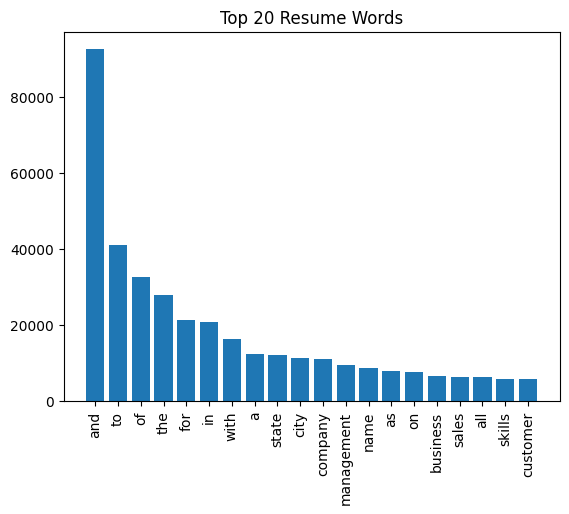

In [16]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

all_resume_text = " ".join(resume_df["Resume_str"].apply(clean_text))
word_counts = Counter(all_resume_text.split())

common_words = word_counts.most_common(20)

words = [w[0] for w in common_words]
counts = [w[1] for w in common_words]

plt.figure()
plt.bar(words, counts)
plt.title("Top 20 Resume Words")
plt.xticks(rotation=90)
plt.show()


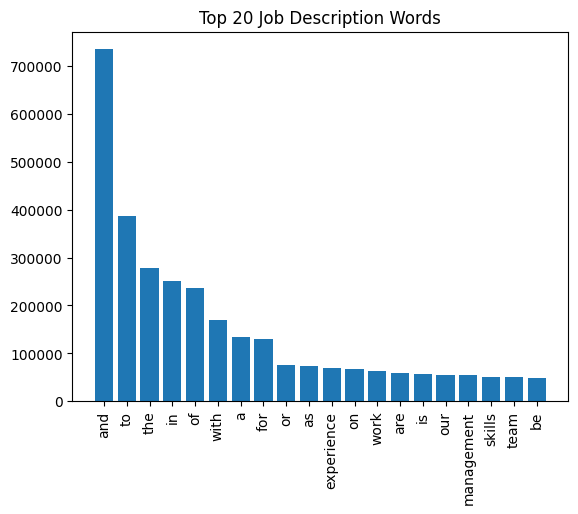

In [17]:
all_job_text = " ".join(job_df["descriptions"].apply(clean_text))
job_word_counts = Counter(all_job_text.split())

common_job_words = job_word_counts.most_common(20)

words = [w[0] for w in common_job_words]
counts = [w[1] for w in common_job_words]

plt.figure()
plt.bar(words, counts)
plt.title("Top 20 Job Description Words")
plt.xticks(rotation=90)
plt.show()


In [18]:
tfidf = TfidfVectorizer(max_features=1000, stop_words='english')

resume_tfidf = tfidf.fit_transform(resume_df["Resume_str"])
job_tfidf = tfidf.transform(job_df["descriptions"])

print("Resume TF-IDF shape:", resume_tfidf.shape)
print("Job TF-IDF shape:", job_tfidf.shape)


Resume TF-IDF shape: (1880, 1000)
Job TF-IDF shape: (42487, 1000)


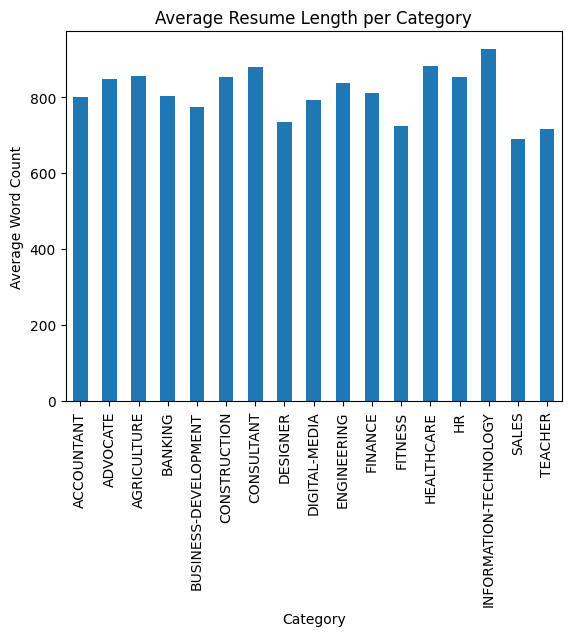

In [19]:
avg_length_per_category = resume_df.groupby("Category")["resume_length"].mean()

plt.figure()
avg_length_per_category.plot(kind='bar')
plt.title("Average Resume Length per Category")
plt.ylabel("Average Word Count")
plt.xticks(rotation=90)
plt.show()


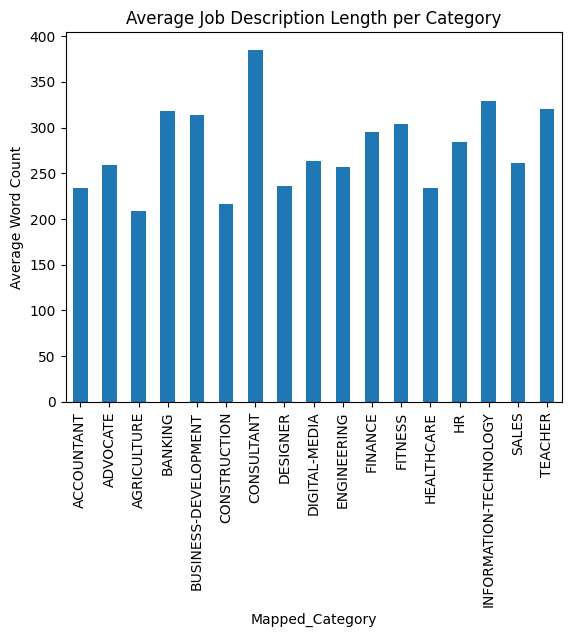

In [20]:
avg_job_length = job_df.groupby("Mapped_Category")["job_length"].mean()

plt.figure()
avg_job_length.plot(kind='bar')
plt.title("Average Job Description Length per Category")
plt.ylabel("Average Word Count")
plt.xticks(rotation=90)
plt.show()


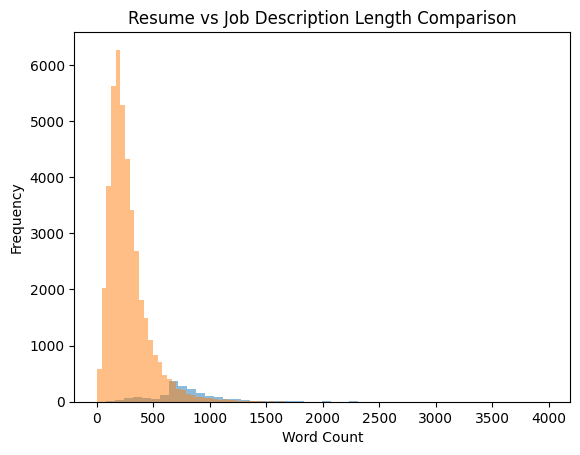

In [21]:
plt.figure()
plt.hist(resume_df["resume_length"], bins=50, alpha=0.5)
plt.hist(job_df["job_length"], bins=50, alpha=0.5)
plt.title("Resume vs Job Description Length Comparison")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()


In [22]:
resume_counts = resume_df["Category"].value_counts()
imbalance_ratio = resume_counts.max() / resume_counts.min()

print("Class Imbalance Ratio (Resumes):", imbalance_ratio)


Class Imbalance Ratio (Resumes): 1.9047619047619047


## 4. Phase I Unsupervised Lexical Retrieval Baseline (TF-IDF + Cosine Matching)
Resumes in the held-out test partition (=376$) are matched against category-aggregated job description TF-IDF centroids via cosine similarity.
Generates the per-class F1 score performance bar chart across all 17 professional domains (**Figure 6** in the manuscript).


Pure Keyword Matching Baseline
Accuracy: 0.4867
Macro F1: 0.4255

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.51      0.83      0.63        24
              ADVOCATE       0.00      0.00      0.00        24
           AGRICULTURE       0.00      0.00      0.00        13
               BANKING       0.71      0.22      0.33        23
  BUSINESS-DEVELOPMENT       0.06      0.04      0.05        24
          CONSTRUCTION       0.48      0.68      0.57        22
            CONSULTANT       0.12      0.04      0.06        23
              DESIGNER       0.65      0.71      0.68        21
         DIGITAL-MEDIA       0.65      0.89      0.76        19
           ENGINEERING       0.82      0.58      0.68        24
               FINANCE       0.00      0.00      0.00        24
               FITNESS       1.00      0.30      0.47        23
            HEALTHCARE       0.42      0.57      0.48        23
              

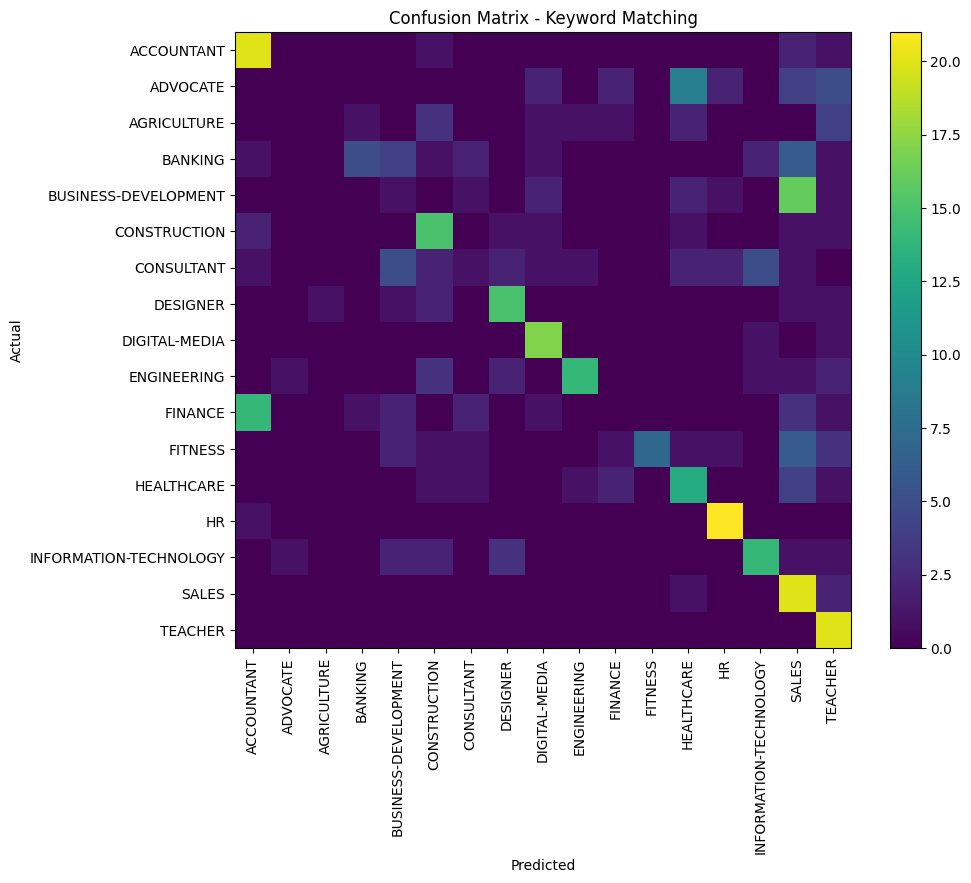

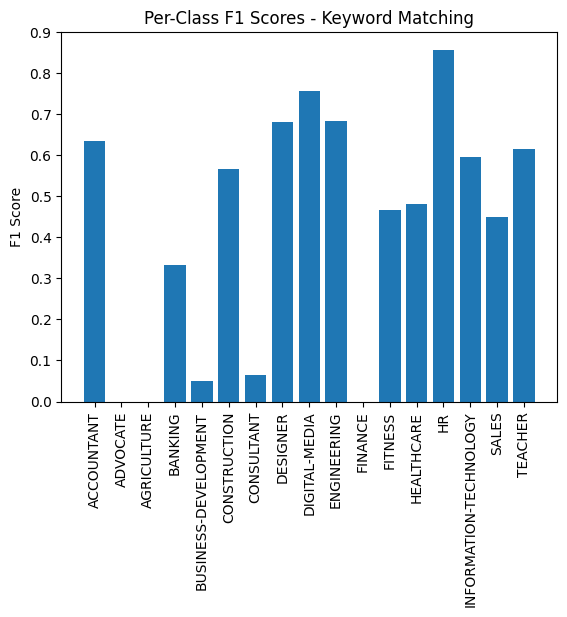

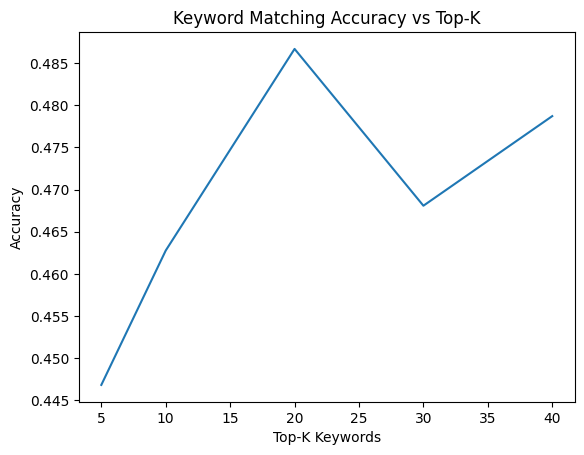

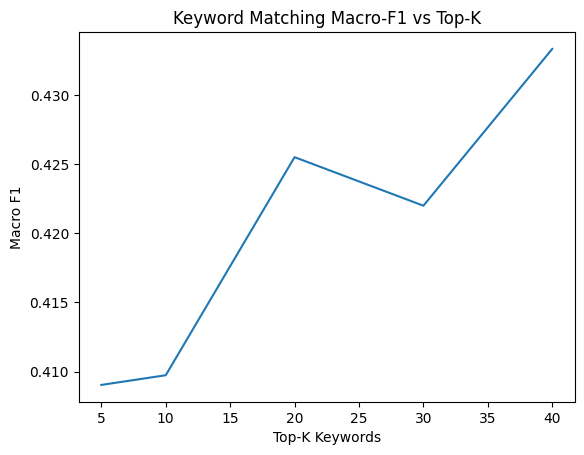


Keyword Top-K Sensitivity Results:
   Top_K  Accuracy  Macro_F1
0      5  0.446809  0.409033
1     10  0.462766  0.409734
2     20  0.486702  0.425515
3     30  0.468085  0.422002
4     40  0.478723  0.433348


In [23]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# -----------------------------
# 1. Load cleaned datasets
# -----------------------------
resume_df = pd.read_csv("clean_resumes.csv")
job_df = pd.read_csv("clean_job_descriptions.csv")

resume_df.columns = resume_df.columns.str.lower()
job_df.columns = job_df.columns.str.lower()

# -----------------------------
# 2. Train/Test Split
# -----------------------------
train_resumes, test_resumes = train_test_split(
    resume_df,
    test_size=0.2,
    stratify=resume_df["category"],
    random_state=42
)

# -----------------------------
# 3. Fit TF-IDF ONLY to extract keywords
# -----------------------------
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1,2)
)

combined_corpus = list(train_resumes["resume_str"]) + list(job_df["descriptions"])
tfidf.fit(combined_corpus)

feature_names = np.array(tfidf.get_feature_names_out())

# -----------------------------
# 4. Extract Top-K Keywords Function
# -----------------------------
def extract_keywords(text, top_k=20):
    vec = tfidf.transform([text])
    scores = vec.toarray().flatten()
    top_indices = scores.argsort()[-top_k:]
    return set(feature_names[top_indices])

# Precompute job keywords
job_keywords = [
    extract_keywords(desc, top_k=20)
    for desc in job_df["descriptions"]
]

job_categories = job_df["mapped_category"].values
unique_categories = sorted(job_df["mapped_category"].unique())

# Group job indices by category
category_indices = {
    cat: np.where(job_categories == cat)[0]
    for cat in unique_categories
}

# -----------------------------
# 5. Keyword Matching Prediction
# -----------------------------
def predict_category(resume_text):
    resume_kw = extract_keywords(resume_text, top_k=20)
    
    category_scores = {}
    
    for cat in unique_categories:
        indices = category_indices[cat]
        overlaps = []
        
        for idx in indices:
            jd_kw = job_keywords[idx]
            overlap_score = len(resume_kw.intersection(jd_kw)) / (len(resume_kw) + 1e-9)
            overlaps.append(overlap_score)
        
        category_scores[cat] = np.mean(overlaps)
    
    return max(category_scores, key=category_scores.get)

# -----------------------------
# 6. Predict on Test Set
# -----------------------------
predictions = []

for text in test_resumes["resume_str"]:
    pred = predict_category(text)
    predictions.append(pred)

# -----------------------------
# 7. Evaluation
# -----------------------------
accuracy = accuracy_score(test_resumes["category"], predictions)
macro_f1 = f1_score(test_resumes["category"], predictions, average="macro")

print("Pure Keyword Matching Baseline")
print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))

print("\nClassification Report:")
print(classification_report(test_resumes["category"], predictions))

# ---------------------------------
# 8. Confusion Matrix
# ---------------------------------
cm = confusion_matrix(
    test_resumes["category"],
    predictions,
    labels=unique_categories
)

plt.figure(figsize=(10,8))
plt.imshow(cm)
plt.title("Confusion Matrix - Keyword Matching")
plt.colorbar()
plt.xticks(range(len(unique_categories)), unique_categories, rotation=90)
plt.yticks(range(len(unique_categories)), unique_categories)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ---------------------------------
# 9. Per-Class F1 Plot
# ---------------------------------
report = classification_report(
    test_resumes["category"],
    predictions,
    output_dict=True
)

class_f1 = {
    label: report[label]["f1-score"]
    for label in unique_categories
}

plt.figure()
plt.bar(class_f1.keys(), class_f1.values())
plt.xticks(rotation=90)
plt.title("Per-Class F1 Scores - Keyword Matching")
plt.ylabel("F1 Score")
plt.show()

# ---------------------------------
# 10. Top-K Sensitivity Analysis
# ---------------------------------
k_values = [5, 10, 20, 30, 40]
k_results = []

for k in k_values:
    job_keywords_k = [
        extract_keywords(desc, top_k=k)
        for desc in job_df["descriptions"]
    ]
    
    preds_k = []
    
    for text in test_resumes["resume_str"]:
        resume_kw = extract_keywords(text, top_k=k)
        category_scores = {}
        
        for cat in unique_categories:
            indices = category_indices[cat]
            overlaps = []
            
            for idx in indices:
                jd_kw = job_keywords_k[idx]
                overlap_score = len(resume_kw.intersection(jd_kw)) / (len(resume_kw) + 1e-9)
                overlaps.append(overlap_score)
            
            category_scores[cat] = np.mean(overlaps)
        
        preds_k.append(max(category_scores, key=category_scores.get))
    
    acc_k = accuracy_score(test_resumes["category"], preds_k)
    f1_k = f1_score(test_resumes["category"], preds_k, average="macro")
    
    k_results.append((k, acc_k, f1_k))

k_df = pd.DataFrame(k_results, columns=["Top_K", "Accuracy", "Macro_F1"])

# Plot Accuracy vs K
plt.figure()
plt.plot(k_df["Top_K"], k_df["Accuracy"])
plt.title("Keyword Matching Accuracy vs Top-K")
plt.xlabel("Top-K Keywords")
plt.ylabel("Accuracy")
plt.show()

# Plot Macro-F1 vs K
plt.figure()
plt.plot(k_df["Top_K"], k_df["Macro_F1"])
plt.title("Keyword Matching Macro-F1 vs Top-K")
plt.xlabel("Top-K Keywords")
plt.ylabel("Macro F1")
plt.show()

print("\nKeyword Top-K Sensitivity Results:")
print(k_df)


TF-IDF + Cosine Similarity Baseline
Accuracy: 0.492
Macro F1: 0.4433


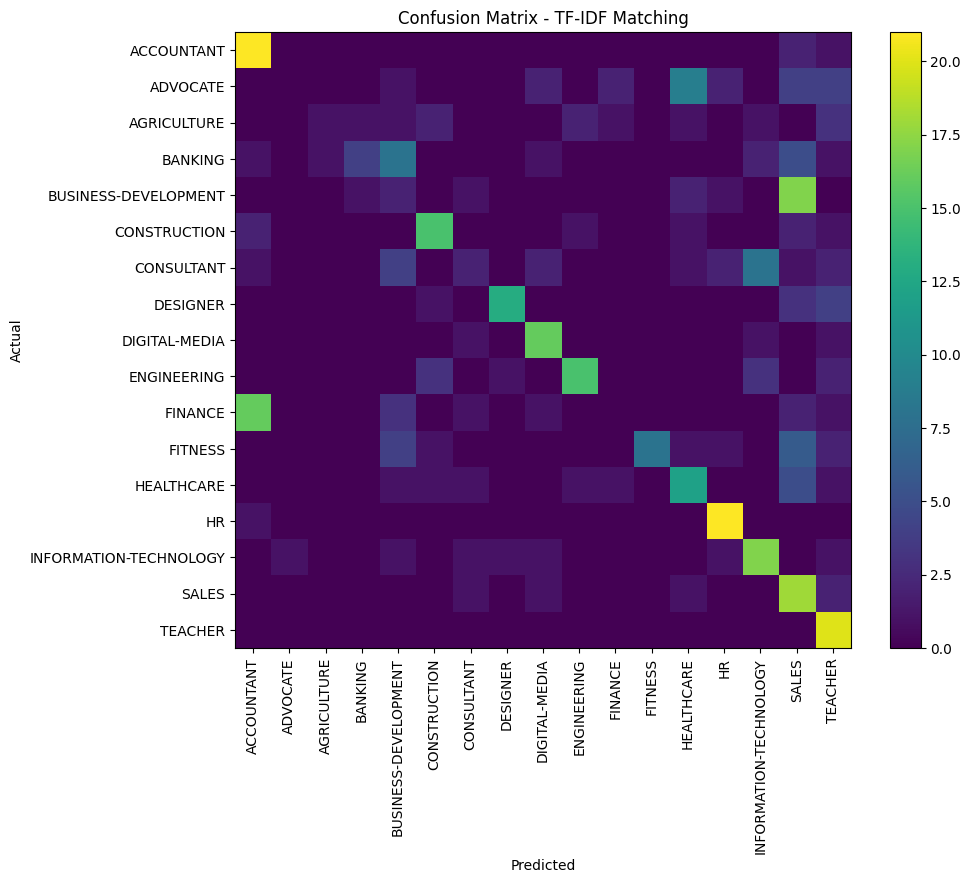

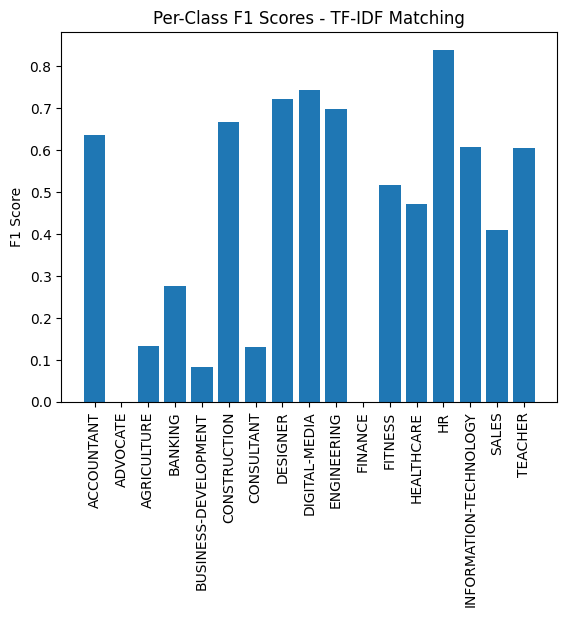

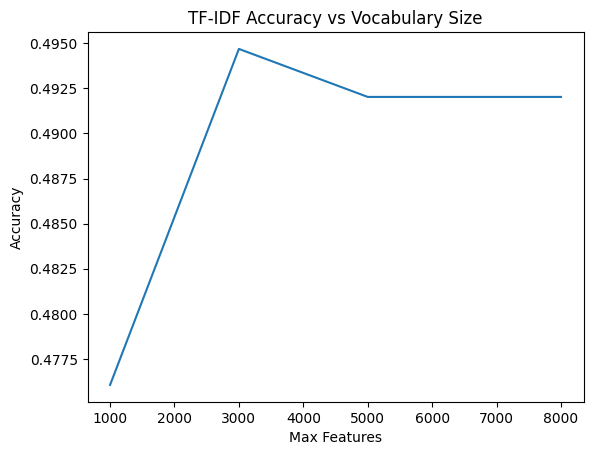

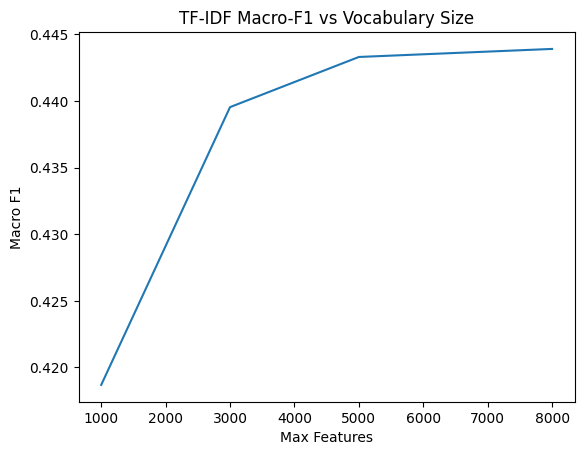


Vocabulary Sensitivity Results:
   Vocab_Size  Accuracy  Macro_F1
0        1000  0.476064  0.418689
1        3000  0.494681  0.439531
2        5000  0.492021  0.443293
3        8000  0.492021  0.443897


In [24]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# -----------------------------
# 1. Load cleaned datasets
# -----------------------------
resume_df = pd.read_csv("clean_resumes.csv")
job_df = pd.read_csv("clean_job_descriptions.csv")

# Standardize column names if needed
resume_df.columns = resume_df.columns.str.lower()
job_df.columns = job_df.columns.str.lower()

# -----------------------------
# 2. Train/Test Split (Resumes)
# -----------------------------
train_resumes, test_resumes = train_test_split(
    resume_df,
    test_size=0.2,
    stratify=resume_df["category"],
    random_state=42
)

# -----------------------------
# 3. Fit TF-IDF on TRAIN resumes + ALL job descriptions
# -----------------------------
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1,2)
)

combined_corpus = list(train_resumes["resume_str"]) + list(job_df["descriptions"])
tfidf.fit(combined_corpus)

# Transform
train_resume_vectors = tfidf.transform(train_resumes["resume_str"])
test_resume_vectors = tfidf.transform(test_resumes["resume_str"])
job_vectors = tfidf.transform(job_df["descriptions"])

# -----------------------------
# 4. Precompute Job Category Groups
# -----------------------------
job_categories = job_df["mapped_category"].values
unique_categories = sorted(job_df["mapped_category"].unique())

# For faster indexing
category_indices = {
    cat: np.where(job_categories == cat)[0]
    for cat in unique_categories
}

# -----------------------------
# 5. Prediction Function
# -----------------------------
def predict_category(resume_vector):
    similarities = cosine_similarity(resume_vector, job_vectors).flatten()
    
    category_scores = {}
    
    for cat in unique_categories:
        indices = category_indices[cat]
        category_scores[cat] = similarities[indices].mean()
    
    return max(category_scores, key=category_scores.get)

# -----------------------------
# 6. Predict on Test Set
# -----------------------------
predictions = []

for i in range(test_resume_vectors.shape[0]):
    pred = predict_category(test_resume_vectors[i])
    predictions.append(pred)

# -----------------------------
# 7. Evaluation
# -----------------------------
accuracy = accuracy_score(test_resumes["category"], predictions)
macro_f1 = f1_score(test_resumes["category"], predictions, average="macro")

print("TF-IDF + Cosine Similarity Baseline")
print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))

# ---------------------------------
# 8. Confusion Matrix
# ---------------------------------
cm = confusion_matrix(
    test_resumes["category"],
    predictions,
    labels=unique_categories
)

plt.figure(figsize=(10,8))
plt.imshow(cm)
plt.title("Confusion Matrix - TF-IDF Matching")
plt.colorbar()
plt.xticks(range(len(unique_categories)), unique_categories, rotation=90)
plt.yticks(range(len(unique_categories)), unique_categories)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ---------------------------------
# 9. Per-Class F1 Plot
# ---------------------------------
report = classification_report(
    test_resumes["category"],
    predictions,
    output_dict=True
)

class_f1 = {
    label: report[label]["f1-score"]
    for label in unique_categories
}

plt.figure()
plt.bar(class_f1.keys(), class_f1.values())
plt.xticks(rotation=90)
plt.title("Per-Class F1 Scores - TF-IDF Matching")
plt.ylabel("F1 Score")
plt.show()

# ---------------------------------
# 10. Vocabulary Size Sensitivity
# ---------------------------------
feature_sizes = [1000, 3000, 5000, 8000]
sweep_results = []

for size in feature_sizes:
    tfidf_sweep = TfidfVectorizer(
        max_features=size,
        stop_words='english',
        ngram_range=(1,2)
    )
    
    tfidf_sweep.fit(combined_corpus)
    
    test_vec = tfidf_sweep.transform(test_resumes["resume_str"])
    job_vec = tfidf_sweep.transform(job_df["descriptions"])
    
    preds = []
    
    for i in range(test_vec.shape[0]):
        sims = cosine_similarity(test_vec[i], job_vec).flatten()
        category_scores = {}
        
        for cat in unique_categories:
            indices = category_indices[cat]
            category_scores[cat] = sims[indices].mean()
        
        preds.append(max(category_scores, key=category_scores.get))
    
    acc = accuracy_score(test_resumes["category"], preds)
    f1 = f1_score(test_resumes["category"], preds, average="macro")
    
    sweep_results.append((size, acc, f1))

sweep_df = pd.DataFrame(sweep_results, columns=["Vocab_Size", "Accuracy", "Macro_F1"])

# Accuracy vs Vocabulary Size
plt.figure()
plt.plot(sweep_df["Vocab_Size"], sweep_df["Accuracy"])
plt.title("TF-IDF Accuracy vs Vocabulary Size")
plt.xlabel("Max Features")
plt.ylabel("Accuracy")
plt.show()

# Macro-F1 vs Vocabulary Size
plt.figure()
plt.plot(sweep_df["Vocab_Size"], sweep_df["Macro_F1"])
plt.title("TF-IDF Macro-F1 vs Vocabulary Size")
plt.xlabel("Max Features")
plt.ylabel("Macro F1")
plt.show()

print("\nVocabulary Sensitivity Results:")
print(sweep_df)



In [25]:
from sklearn.metrics import classification_report

print("\nClassification Report:")
print(classification_report(test_resumes["category"], predictions))

print(set(test_resumes["category"]) - set(unique_categories))



Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.50      0.88      0.64        24
              ADVOCATE       0.00      0.00      0.00        24
           AGRICULTURE       0.50      0.08      0.13        13
               BANKING       0.67      0.17      0.28        23
  BUSINESS-DEVELOPMENT       0.08      0.08      0.08        24
          CONSTRUCTION       0.65      0.68      0.67        22
            CONSULTANT       0.25      0.09      0.13        23
              DESIGNER       0.87      0.62      0.72        21
         DIGITAL-MEDIA       0.67      0.84      0.74        19
           ENGINEERING       0.79      0.62      0.70        24
               FINANCE       0.00      0.00      0.00        24
               FITNESS       1.00      0.35      0.52        23
            HEALTHCARE       0.43      0.52      0.47        23
                    HR       0.75      0.95      0.84        22
INFORMATION-TEC

## 5. Phase I Dense Semantic & Unsupervised Linear Hybrid Retrieval
Evaluating MPNet dense semantic centroid matching and linear hybrid combination:
S_{\\text{hybrid}}(c) = \\alpha \\cdot S_{\\text{semantic}}(c) + (1-\\alpha) \\cdot S_{\\text{lexical}}(c)
Performs an empirical grid search over $\\alpha \\in [0.0, 1.0]$ in increments of 0.05, identifying optimal $\\alpha = 0.90$ (53.99% accuracy, 0.5158 Macro F1).
Generates the diagnostic confusion matrix (**Figure 8** in the manuscript, HybridConfMatrix.png).


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (3 outputs left out)

Encoding test resumes...


100%|██████████| 24/24 [00:06<00:00,  3.86it/s]



BERT-Only Semantic Matching Baseline
Accuracy: 0.2766
Macro F1: 0.2586

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.75      0.50      0.60        24
              ADVOCATE       0.00      0.00      0.00        24
           AGRICULTURE       1.00      0.08      0.14        13
               BANKING       0.00      0.00      0.00        23
  BUSINESS-DEVELOPMENT       0.00      0.00      0.00        24
          CONSTRUCTION       0.60      0.27      0.38        22
            CONSULTANT       0.10      0.17      0.12        23
              DESIGNER       0.65      0.52      0.58        21
         DIGITAL-MEDIA       0.71      0.26      0.38        19
           ENGINEERING       0.62      0.21      0.31        24
               FINANCE       0.11      0.71      0.20        24
               FITNESS       0.00      0.00      0.00        23
            HEALTHCARE       0.33      0.13      0.19        23
       

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


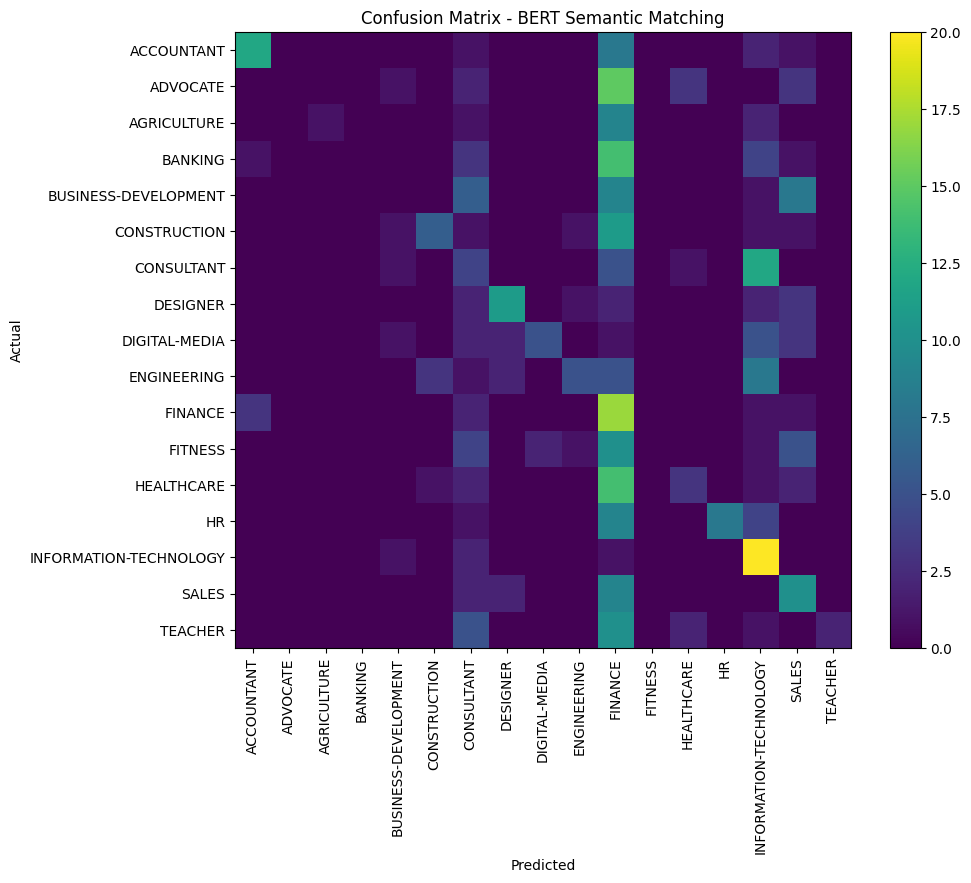

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


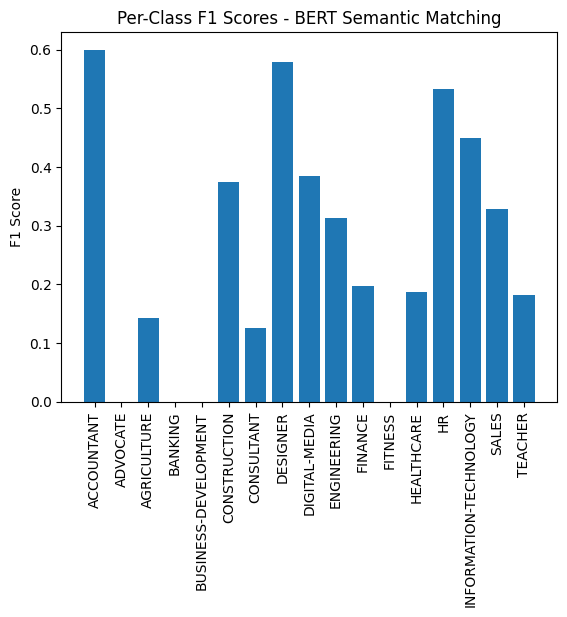

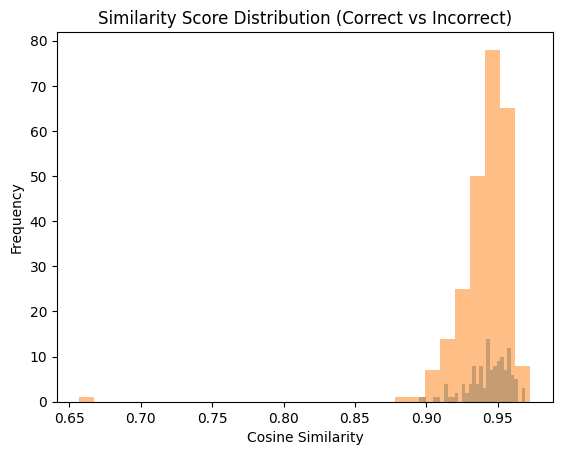

Encoding with CLS pooling...


100%|██████████| 24/24 [00:06<00:00,  3.87it/s]


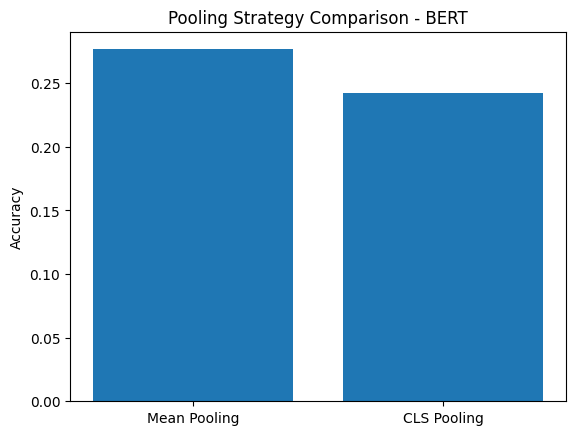


Pooling Comparison:
Mean Pooling Accuracy: 0.2766
CLS Pooling Accuracy: 0.242


In [26]:
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# -----------------------------
# 1. Load cleaned datasets
# -----------------------------
resume_df = pd.read_csv("clean_resumes.csv")
job_df = pd.read_csv("clean_job_descriptions.csv")

resume_df.columns = resume_df.columns.str.lower()
job_df.columns = job_df.columns.str.lower()

# -----------------------------
# 2. Train/Test Split
# -----------------------------
train_resumes, test_resumes = train_test_split(
    resume_df,
    test_size=0.2,
    stratify=resume_df["category"],
    random_state=42
)

# -----------------------------
# 3. Load Pretrained BERT
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased")
model.to(device)
model.eval()

# -----------------------------
# 4. Sentence Embedding Function (Mean Pooling)
# -----------------------------
def get_embeddings(text_list, batch_size=16):
    embeddings = []
    
    for i in tqdm(range(0, len(text_list), batch_size)):
        batch = text_list[i:i+batch_size]
        
        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)
        
        with torch.no_grad():
            outputs = model(**inputs)
        
        last_hidden = outputs.last_hidden_state
        
        # Mean pooling
        attention_mask = inputs["attention_mask"].unsqueeze(-1)
        masked_hidden = last_hidden * attention_mask
        summed = torch.sum(masked_hidden, dim=1)
        counts = torch.clamp(attention_mask.sum(dim=1), min=1e-9)
        mean_pooled = summed / counts
        
        embeddings.append(mean_pooled.cpu().numpy())
    
    return np.vstack(embeddings)

# -----------------------------
# 5. Compute Embeddings
# -----------------------------
print("Encoding job descriptions...")
job_embeddings = get_embeddings(job_df["descriptions"].tolist())

print("Encoding test resumes...")
test_resume_embeddings = get_embeddings(test_resumes["resume_str"].tolist())

# -----------------------------
# 6. Prepare Category Indexing
# -----------------------------
job_categories = job_df["mapped_category"].values
unique_categories = sorted(job_df["mapped_category"].unique())

category_indices = {
    cat: np.where(job_categories == cat)[0]
    for cat in unique_categories
}

# -----------------------------
# 7. Prediction Function
# -----------------------------
def predict_category(resume_embedding):
    similarities = cosine_similarity(
        resume_embedding.reshape(1, -1),
        job_embeddings
    ).flatten()
    
    category_scores = {}
    
    for cat in unique_categories:
        indices = category_indices[cat]
        category_scores[cat] = similarities[indices].mean()
    
    return max(category_scores, key=category_scores.get)

# -----------------------------
# 8. Predict on Test Set
# -----------------------------
predictions = []

for i in range(len(test_resume_embeddings)):
    pred = predict_category(test_resume_embeddings[i])
    predictions.append(pred)

# -----------------------------
# 9. Evaluation
# -----------------------------
accuracy = accuracy_score(test_resumes["category"], predictions)
macro_f1 = f1_score(test_resumes["category"], predictions, average="macro")

print("\nBERT-Only Semantic Matching Baseline")
print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))

print("\nClassification Report:")
print(classification_report(test_resumes["category"], predictions))

# ---------------------------------
# 10. Confusion Matrix
# ---------------------------------
cm = confusion_matrix(
    test_resumes["category"],
    predictions,
    labels=unique_categories
)

plt.figure(figsize=(10,8))
plt.imshow(cm)
plt.title("Confusion Matrix - BERT Semantic Matching")
plt.colorbar()
plt.xticks(range(len(unique_categories)), unique_categories, rotation=90)
plt.yticks(range(len(unique_categories)), unique_categories)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ---------------------------------
# 11. Per-Class F1 Plot
# ---------------------------------
report = classification_report(
    test_resumes["category"],
    predictions,
    output_dict=True
)

class_f1 = {
    label: report[label]["f1-score"]
    for label in unique_categories
}

plt.figure()
plt.bar(class_f1.keys(), class_f1.values())
plt.xticks(rotation=90)
plt.title("Per-Class F1 Scores - BERT Semantic Matching")
plt.ylabel("F1 Score")
plt.show()

# ---------------------------------
# 12. Similarity Distribution Analysis
# ---------------------------------
correct_sims = []
incorrect_sims = []

for i in range(len(test_resume_embeddings)):
    sims = cosine_similarity(
        test_resume_embeddings[i].reshape(1, -1),
        job_embeddings
    ).flatten()

    best_idx = np.argmax(sims)
    predicted_label = job_categories[best_idx]
    true_label = test_resumes["category"].iloc[i]

    if predicted_label == true_label:
        correct_sims.append(np.max(sims))
    else:
        incorrect_sims.append(np.max(sims))

plt.figure()
plt.hist(correct_sims, bins=30, alpha=0.5)
plt.hist(incorrect_sims, bins=30, alpha=0.5)
plt.title("Similarity Score Distribution (Correct vs Incorrect)")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.show()

# ---------------------------------
# 13. Pooling Strategy Comparison
# ---------------------------------
def get_cls_embeddings(text_list, batch_size=16):
    embeddings = []
    for i in tqdm(range(0, len(text_list), batch_size)):
        batch = text_list[i:i+batch_size]
        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)
        with torch.no_grad():
            outputs = model(**inputs)

        cls_embeddings = outputs.last_hidden_state[:, 0, :]
        embeddings.append(cls_embeddings.cpu().numpy())

    return np.vstack(embeddings)

print("Encoding with CLS pooling...")
job_cls = get_cls_embeddings(job_df["descriptions"].tolist())
test_cls = get_cls_embeddings(test_resumes["resume_str"].tolist())

cls_predictions = []

for i in range(len(test_cls)):
    sims = cosine_similarity(
        test_cls[i].reshape(1, -1),
        job_cls
    ).flatten()

    category_scores = {}
    for cat in unique_categories:
        indices = category_indices[cat]
        category_scores[cat] = sims[indices].mean()

    cls_predictions.append(max(category_scores, key=category_scores.get))

cls_acc = accuracy_score(test_resumes["category"], cls_predictions)
cls_f1 = f1_score(test_resumes["category"], cls_predictions, average="macro")

# Plot comparison
plt.figure()
plt.bar(["Mean Pooling", "CLS Pooling"], [accuracy, cls_acc])
plt.title("Pooling Strategy Comparison - BERT")
plt.ylabel("Accuracy")
plt.show()

print("\nPooling Comparison:")
print("Mean Pooling Accuracy:", round(accuracy, 4))
print("CLS Pooling Accuracy:", round(cls_acc, 4))


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

... (8 outputs left out)

100%|██████████| 42487/42487 [23:39<00:00, 29.93it/s]


Job Embedding Shape: (42487, 768)
Evaluating semantic model...


100%|██████████| 376/376 [01:22<00:00,  4.57it/s]
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Improved Semantic Matching (Sentence-BERT)
Accuracy: 0.516
Macro F1: 0.4559

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.43      0.96      0.60        24
              ADVOCATE       0.00      0.00      0.00        24
           AGRICULTURE       1.00      0.31      0.47        13
               BANKING       0.74      0.61      0.67        23
  BUSINESS-DEVELOPMENT       0.00      0.00      0.00        24
          CONSTRUCTION       0.89      0.36      0.52        22
            CONSULTANT       0.00      0.00      0.00        23
              DESIGNER       0.86      0.57      0.69        21
         DIGITAL-MEDIA       0.90      0.47      0.62        19
           ENGINEERING       0.52      0.92      0.67        24
               FINANCE       0.00      0.00      0.00        24
               FITNESS       1.00      0.35      0.52        23
            HEALTHCARE       0.38      0.57      0.46        23
  

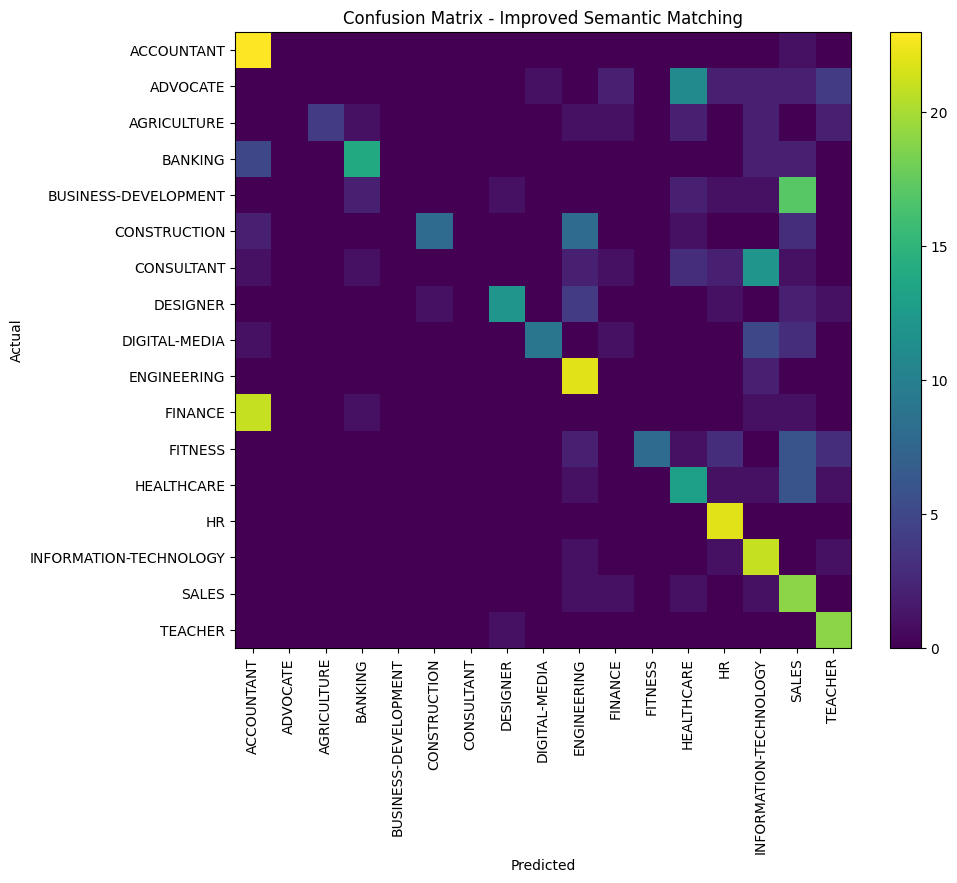

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


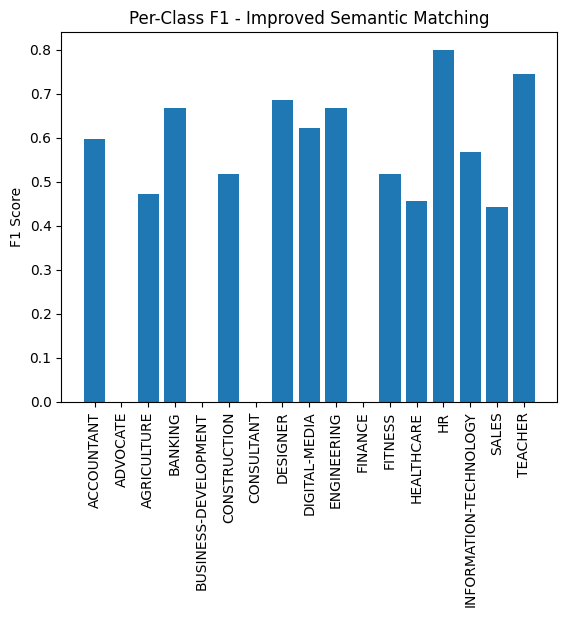

In [27]:
import pandas as pd
import numpy as np
import torch
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tqdm import tqdm

# =====================================================
# 1. LOAD & CLEAN DATA
# =====================================================
resume_df = pd.read_csv("clean_resumes.csv")
job_df = pd.read_csv("clean_job_descriptions.csv")

resume_df.columns = resume_df.columns.str.lower()
job_df.columns = job_df.columns.str.lower()

# Clean text fields
resume_df["resume_str"] = resume_df["resume_str"].fillna("").astype(str)
job_df["descriptions"] = job_df["descriptions"].fillna("").astype(str)

resume_df = resume_df[resume_df["resume_str"].str.strip() != ""]
job_df = job_df[job_df["descriptions"].str.strip() != ""]

train_resumes, test_resumes = train_test_split(
    resume_df,
    test_size=0.2,
    stratify=resume_df["category"],
    random_state=42
)

# =====================================================
# 2. LOAD SENTENCE-BERT (OPTIMIZED)
# =====================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer("all-mpnet-base-v2", device=device)

# =====================================================
# 3. ROBUST CHUNKING FUNCTION
# =====================================================
def chunk_text(text, chunk_size=400, overlap=50):
    words = str(text).split()
    if len(words) == 0:
        return []
    step = chunk_size - overlap
    return [
        " ".join(words[i:i+chunk_size])
        for i in range(0, len(words), step)
        if len(words[i:i+chunk_size]) > 5
    ]

def encode_long_text(text):
    # Split text into chunks if necessary
    chunks = chunk_text(text)

    # If no chunks, just encode the full text
    if len(chunks) == 0:
        return model.encode(str(text), convert_to_numpy=True)

    # Encode all chunks
    embeddings = model.encode(chunks, convert_to_numpy=True, show_progress_bar=False)

    # If embeddings is 1D (single chunk), return as is
    if embeddings.ndim == 1:
        return embeddings

    # If multiple chunks, return the mean embedding
    return np.mean(embeddings, axis=0)


# =====================================================
# 4. ENCODE JOB DESCRIPTIONS (ONCE)
# =====================================================
print("Encoding job descriptions...")
job_embeddings = []

for desc in tqdm(job_df["descriptions"].tolist()):
    job_embeddings.append(encode_long_text(desc))

job_embeddings = np.vstack(job_embeddings)
print("Job Embedding Shape:", job_embeddings.shape)

# =====================================================
# 5. CATEGORY INDEXING + CENTROIDS
# =====================================================
job_categories = job_df["mapped_category"].values
unique_categories = sorted(np.unique(job_categories))

category_indices = {
    cat: np.where(job_categories == cat)[0]
    for cat in unique_categories
}

# Category centroid embeddings
category_centroids = {}

for cat in unique_categories:
    indices = category_indices[cat]
    category_centroids[cat] = np.mean(job_embeddings[indices], axis=0)

# =====================================================
# 6. PREDICTION FUNCTION (TOP-K + CENTROID)
# =====================================================
def predict_category(resume_text, top_k=10):
    resume_embedding = encode_long_text(resume_text)
    
    similarities = cosine_similarity(
        resume_embedding.reshape(1, -1),
        job_embeddings
    ).flatten()
    
    category_scores = {}
    
    for cat in unique_categories:
        indices = category_indices[cat]
        
        # Top-K similarity aggregation
        top_sim = np.sort(similarities[indices])[-top_k:]
        topk_score = np.mean(top_sim)
        
        # Centroid similarity
        centroid_sim = cosine_similarity(
            resume_embedding.reshape(1, -1),
            category_centroids[cat].reshape(1, -1)
        )[0][0]
        
        # Weighted combination
        category_scores[cat] = 0.7 * topk_score + 0.3 * centroid_sim
    
    return max(category_scores, key=category_scores.get)

# =====================================================
# 7. EVALUATION
# =====================================================
print("Evaluating semantic model...")
predictions = []

for text in tqdm(test_resumes["resume_str"].tolist()):
    predictions.append(predict_category(text))

accuracy = accuracy_score(test_resumes["category"], predictions)
macro_f1 = f1_score(test_resumes["category"], predictions, average="macro")

print("\nImproved Semantic Matching (Sentence-BERT)")
print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))
print("\nClassification Report:")
print(classification_report(test_resumes["category"], predictions))

# =====================================================
# 8. CONFUSION MATRIX
# =====================================================
cm = confusion_matrix(
    test_resumes["category"],
    predictions,
    labels=unique_categories
)

plt.figure(figsize=(10,8))
plt.imshow(cm)
plt.title("Confusion Matrix - Improved Semantic Matching")
plt.colorbar()
plt.xticks(range(len(unique_categories)), unique_categories, rotation=90)
plt.yticks(range(len(unique_categories)), unique_categories)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# =====================================================
# 9. PER-CLASS F1 PLOT
# =====================================================
report = classification_report(
    test_resumes["category"],
    predictions,
    output_dict=True
)

class_f1 = {
    label: report[label]["f1-score"]
    for label in unique_categories
}

plt.figure()
plt.bar(class_f1.keys(), class_f1.values())
plt.xticks(rotation=90)
plt.title("Per-Class F1 - Improved Semantic Matching")
plt.ylabel("F1 Score")
plt.show()


Encoding job descriptions (BERT)...
Encoding test resumes (BERT)...

Starting Hybrid Alpha Tuning...

Alpha: 0.00 | Accuracy: 0.4920 | Macro-F1: 0.4426
Alpha: 0.10 | Accuracy: 0.5053 | Macro-F1: 0.4616
Alpha: 0.20 | Accuracy: 0.5186 | Macro-F1: 0.4779
Alpha: 0.30 | Accuracy: 0.5239 | Macro-F1: 0.4848
Alpha: 0.40 | Accuracy: 0.5239 | Macro-F1: 0.4903
Alpha: 0.50 | Accuracy: 0.5293 | Macro-F1: 0.4947
Alpha: 0.60 | Accuracy: 0.5372 | Macro-F1: 0.5025
Alpha: 0.70 | Accuracy: 0.5319 | Macro-F1: 0.5020
Alpha: 0.80 | Accuracy: 0.5293 | Macro-F1: 0.5029
Alpha: 0.90 | Accuracy: 0.5399 | Macro-F1: 0.5158
Alpha: 1.00 | Accuracy: 0.5266 | Macro-F1: 0.5011

Hybrid training logs saved as hybrid_alpha_logs.csv


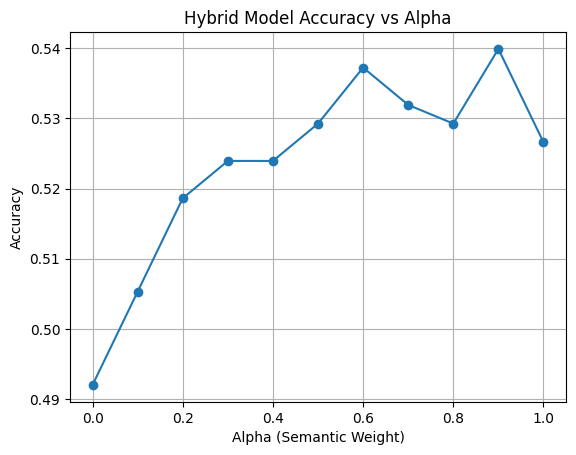

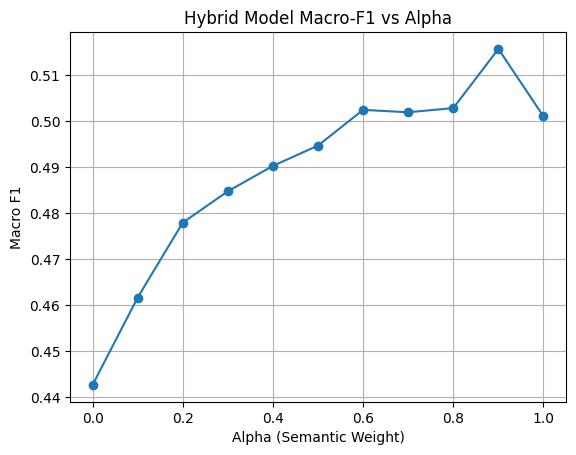


Best Alpha: 0.9


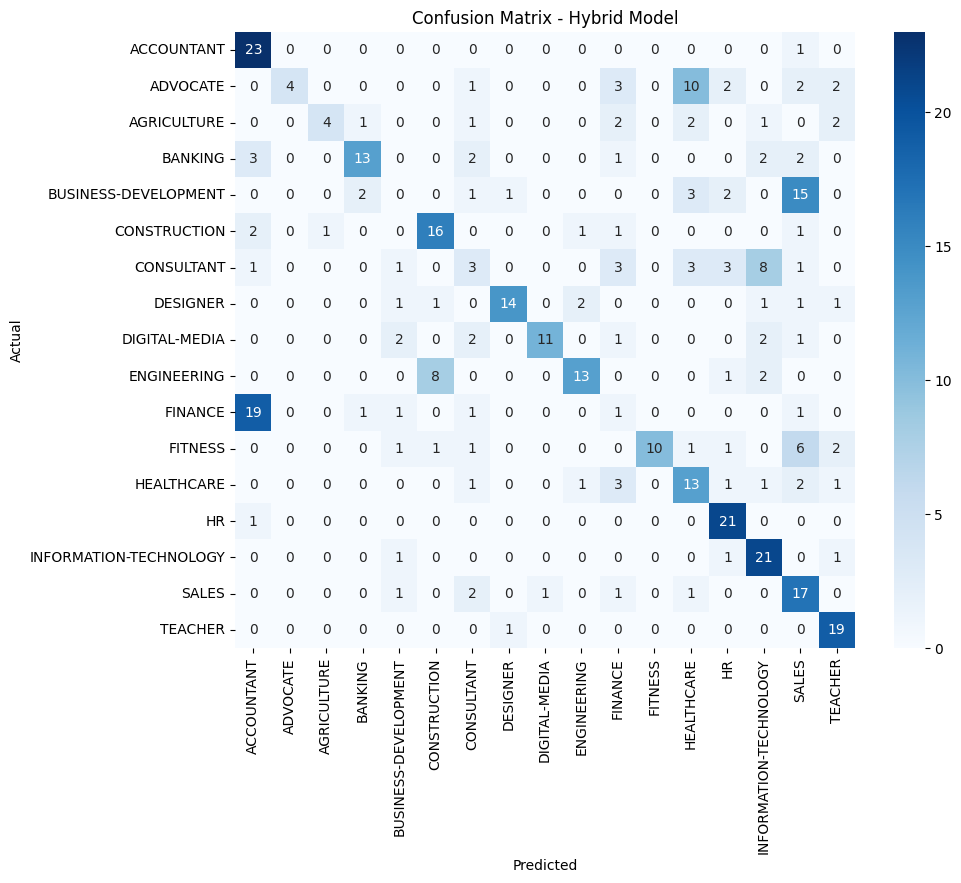

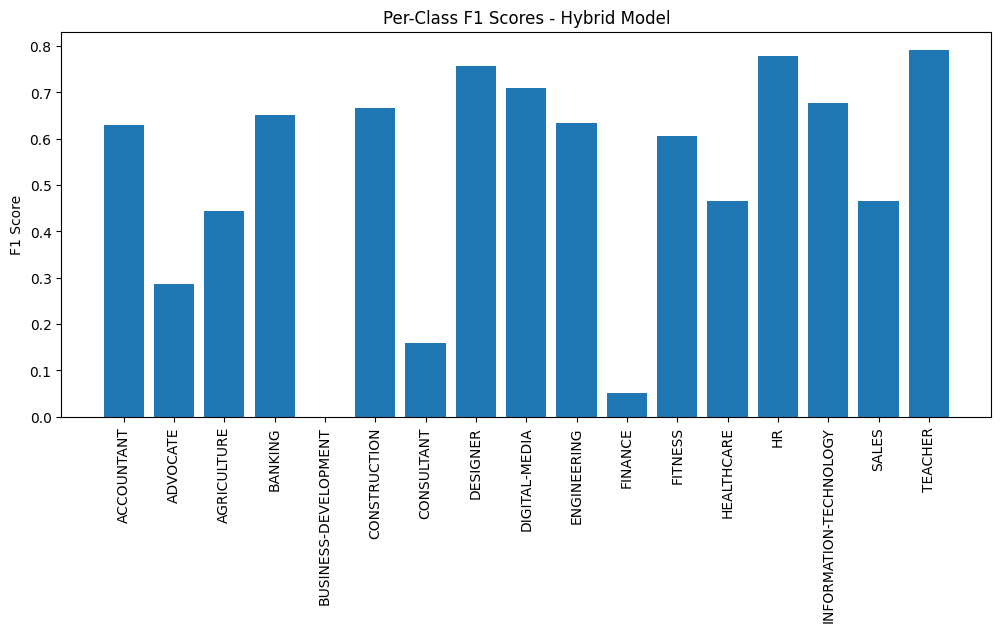

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# =====================================================
# 0. Make sure model and chunk_text are loaded from previous cell
# =====================================================
# model = SentenceTransformer("all-mpnet-base-v2", device=device)
# def chunk_text(text, chunk_size=400, overlap=50): ...
# def encode_long_text(text): ...

# =====================================================
# 0. Define get_embeddings to safely handle long texts
# =====================================================
def get_embeddings(texts):
    embeddings = []
    for t in texts:
        chunks = chunk_text(t)
        if len(chunks) == 0:
            emb = model.encode(str(t), convert_to_numpy=True)
        else:
            chunk_embs = model.encode(chunks, convert_to_numpy=True, show_progress_bar=False)
            if chunk_embs.ndim == 1:
                emb = chunk_embs
            else:
                emb = np.mean(chunk_embs, axis=0)
        embeddings.append(emb)
    return np.vstack(embeddings)

# =====================================================
# 1. TF-IDF REPRESENTATIONS
# =====================================================
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1,2)
)

combined_corpus = list(train_resumes["resume_str"]) + list(job_df["descriptions"])
tfidf.fit(combined_corpus)

test_tfidf = tfidf.transform(test_resumes["resume_str"])
job_tfidf = tfidf.transform(job_df["descriptions"])

# =====================================================
# 2. BERT EMBEDDINGS
# =====================================================
print("Encoding job descriptions (BERT)...")
job_bert = get_embeddings(job_df["descriptions"].tolist())

print("Encoding test resumes (BERT)...")
test_bert = get_embeddings(test_resumes["resume_str"].tolist())

# =====================================================
# 3. CATEGORY INDICES
# =====================================================
job_categories = job_df["mapped_category"].values
unique_categories = sorted(np.unique(job_categories))

category_indices = {
    cat: np.where(job_categories == cat)[0]
    for cat in unique_categories
}

# =====================================================
# 4. HYBRID ALPHA TUNING
# =====================================================
alphas = np.linspace(0.0, 1.0, 11)
results = []

print("\nStarting Hybrid Alpha Tuning...\n")

for alpha in alphas:
    predictions = []

    for i in range(len(test_resumes)):
        tfidf_sim = cosine_similarity(test_tfidf[i], job_tfidf).flatten()
        bert_sim = cosine_similarity(test_bert[i].reshape(1, -1), job_bert).flatten()

        # Normalize similarities
        tfidf_sim = (tfidf_sim - tfidf_sim.min()) / (tfidf_sim.max() - tfidf_sim.min() + 1e-9)
        bert_sim = (bert_sim - bert_sim.min()) / (bert_sim.max() - bert_sim.min() + 1e-9)

        # Compute per-category scores
        category_scores = {}
        for cat in unique_categories:
            indices = category_indices[cat]
            lexical_score = tfidf_sim[indices].mean()
            semantic_score = bert_sim[indices].mean()
            category_scores[cat] = alpha * semantic_score + (1 - alpha) * lexical_score

        # Pick highest scoring category
        pred = max(category_scores, key=category_scores.get)
        predictions.append(pred)

    acc = accuracy_score(test_resumes["category"], predictions)
    f1 = f1_score(test_resumes["category"], predictions, average="macro")

    results.append((alpha, acc, f1))
    print(f"Alpha: {alpha:.2f} | Accuracy: {acc:.4f} | Macro-F1: {f1:.4f}")

# =====================================================
# 5. SAVE RESULTS
# =====================================================
results_df = pd.DataFrame(results, columns=["Alpha", "Accuracy", "Macro_F1"])
results_df.to_csv("hybrid_alpha_logs.csv", index=False)
print("\nHybrid training logs saved as hybrid_alpha_logs.csv")

# =====================================================
# 6. PLOTS
# =====================================================
plt.figure()
plt.plot(results_df["Alpha"], results_df["Accuracy"], marker='o')
plt.title("Hybrid Model Accuracy vs Alpha")
plt.xlabel("Alpha (Semantic Weight)")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

plt.figure()
plt.plot(results_df["Alpha"], results_df["Macro_F1"], marker='o')
plt.title("Hybrid Model Macro-F1 vs Alpha")
plt.xlabel("Alpha (Semantic Weight)")
plt.ylabel("Macro F1")
plt.grid(True)
plt.show()

# =====================================================
# 7. BEST ALPHA PREDICTIONS
# =====================================================
best_alpha = results_df.loc[results_df["Macro_F1"].idxmax(), "Alpha"]
print("\nBest Alpha:", best_alpha)

final_predictions = []
for i in range(len(test_resumes)):
    tfidf_sim = cosine_similarity(test_tfidf[i], job_tfidf).flatten()
    bert_sim = cosine_similarity(test_bert[i].reshape(1, -1), job_bert).flatten()

    tfidf_sim = (tfidf_sim - tfidf_sim.min()) / (tfidf_sim.max() - tfidf_sim.min() + 1e-9)
    bert_sim = (bert_sim - bert_sim.min()) / (bert_sim.max() - bert_sim.min() + 1e-9)

    category_scores = {}
    for cat in unique_categories:
        indices = category_indices[cat]
        lexical_score = tfidf_sim[indices].mean()
        semantic_score = bert_sim[indices].mean()
        category_scores[cat] = best_alpha * semantic_score + (1 - best_alpha) * lexical_score

    pred = max(category_scores, key=category_scores.get)
    final_predictions.append(pred)

# =====================================================
# 8. CONFUSION MATRIX
# =====================================================
cm = confusion_matrix(test_resumes["category"], final_predictions, labels=unique_categories)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=unique_categories, yticklabels=unique_categories, cmap="Blues")
plt.title("Confusion Matrix - Hybrid Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# =====================================================
# 9. PER-CLASS F1
# =====================================================
report = classification_report(test_resumes["category"], final_predictions, output_dict=True)
class_f1 = {k: v["f1-score"] for k, v in report.items() if k in unique_categories}

plt.figure(figsize=(12,5))
plt.bar(class_f1.keys(), class_f1.values())
plt.xticks(rotation=90)
plt.title("Per-Class F1 Scores - Hybrid Model")
plt.ylabel("F1 Score")
plt.show()
